<a href="https://colab.research.google.com/github/KrithikChidM/PrmlLab/blob/main/Lab6/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

In [2]:
means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([4.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),
    np.eye(2),
    np.diag([1.5, 0.5])
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]

class_covariances = [covariances, covariances_2]

covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [3]:
def uniform():
    return max(random.random(), 1e-12)

def box_muller():
    u1 = uniform()
    u2 = uniform()
    r = math.sqrt(-2 * math.log(u1))
    theta = 2 * math.pi * u2
    z1 = r * math.cos(theta)
    z2 = r * math.sin(theta)
    return z1, z2

In [4]:
def gaussian_density(x, mean, C):
    a, b = C[0]
    c, d = C[1]

    det = a*d - b*c

    dx = x[0] - mean[0]
    dy = x[1] - mean[1]

    q = (d*dx*dx - (b+c)*dx*dy + a*dy*dy) / det

    return math.exp(-0.5*q) / (2*math.pi*math.sqrt(det))

In [5]:
def gmm_density(x, means, covariances, weights):
    p = 0.0

    for i in range(K):
        p += weights[i] * gaussian_density(
            x, means[i], covariances[i]
        )

    return p

In [6]:
def generate_component(mean, C):
    z1, z2 = box_muller()

    a, b = C[0]
    c, d = C[1]

    l11 = math.sqrt(a)
    l21 = c / l11
    l22 = math.sqrt(max(d - l21*l21, 0.0))

    x1 = mean[0] + l11*z1
    x2 = mean[1] + l21*z1 + l22*z2

    return [x1, x2]

In [7]:
def generate_gmm_data(means, covariances, weights, n):
    X = []
    component_labels = []

    for _ in range(n):
        u = uniform()

        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2

        x = generate_component(means[k], covariances[k])

        X.append(x)
        component_labels.append(k)

    return np.array(X), np.array(component_labels)

In [8]:
class_data = []
class_component_labels = []

for cls in range(2):
    X, component_labels = generate_gmm_data(
        class_means[cls],
        class_covariances[cls],
        weights,
        n
    )

    class_data.append(X)
    class_component_labels.append(component_labels)

for cls in range(2):
    print("Class", cls)
    print("Total points:", len(class_data[cls]))

    for k in range(K):
        print(
            covariance_names[cls][k],
            "points:",
            np.sum(class_component_labels[cls] == k)
        )

    print()

Class 0
Total points: 5000
Full (+tilt) points: 2437
Isotropic points: 1529
Diagonal points: 1034

Class 1
Total points: 5000
Full (-tilt) points: 2537
Isotropic points: 1454
Full (-tilt) points: 1009



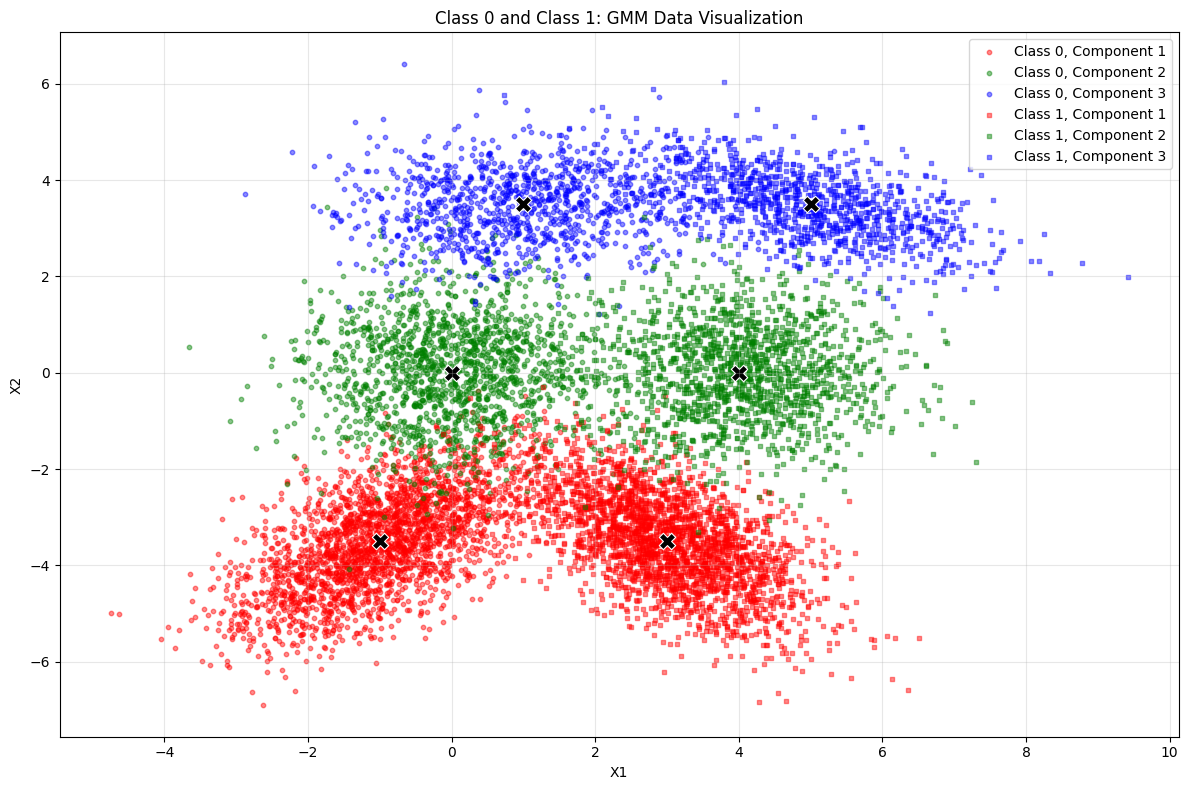

In [10]:
plt.figure(figsize=(12, 8))

colors = ["red", "green", "blue"]
markers = ["o", "s"]

for cls in range(2):
    X = class_data[cls]
    labels = class_component_labels[cls]

    for k in range(K):
        points = X[labels == k]
        plt.scatter(
            points[:, 0], points[:, 1],
            color=colors[k], marker=markers[cls],
            s=10, alpha=0.45,
            label=f"Class {cls}, Component {k + 1}"
        )

    for k in range(K):
        plt.scatter(
            class_means[cls][k][0], class_means[cls][k][1],
            color="black", marker="X", s=140,
            edgecolors="white", linewidths=0.8
        )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Class 0 and Class 1: GMM Data Visualization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

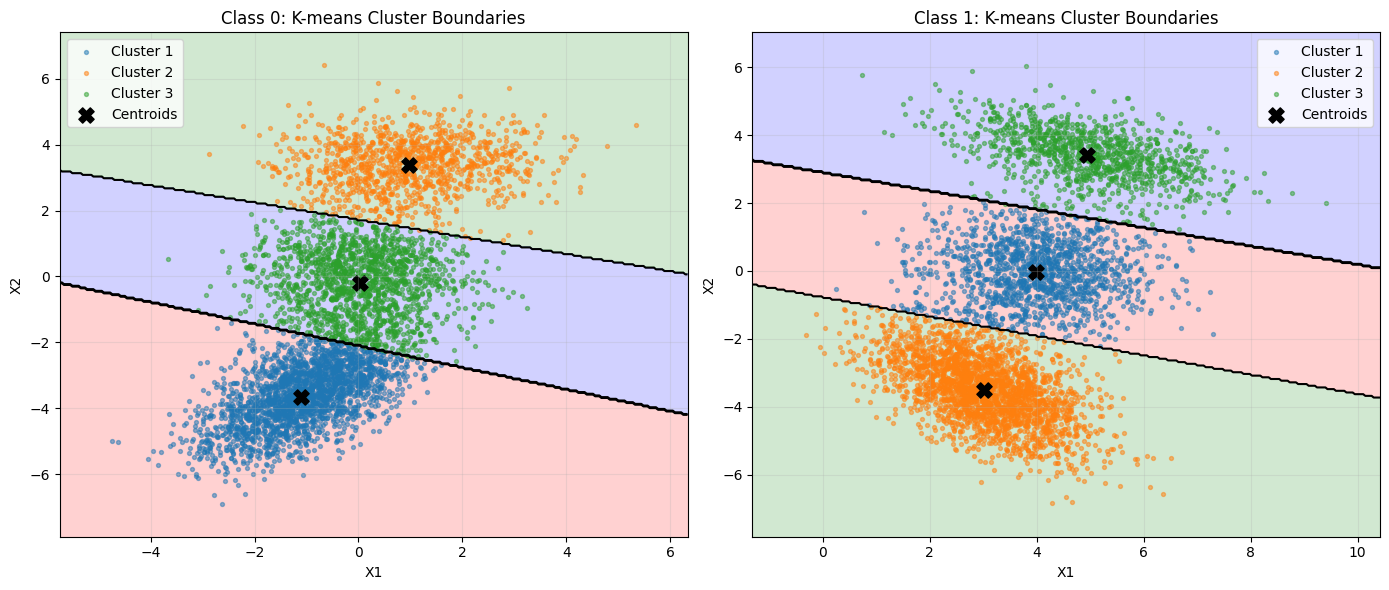

In [11]:
from sklearn.cluster import KMeans
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for cls, ax in enumerate(axes):
    X = class_data[cls]
    kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = kmeans.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z, alpha=0.18,
        cmap=ListedColormap(["red", "green", "blue"])
    )
    ax.contour(
        xx, yy, Z, levels=np.arange(K - 1) + 0.5,
        colors="black", linewidths=1.5
    )

    for k in range(K):
        points = X[cluster_labels == k]
        ax.scatter(
            points[:, 0], points[:, 1],
            s=8, alpha=0.5,
            label=f"Cluster {k + 1}"
        )

    ax.scatter(
        kmeans.cluster_centers_[:, 0],
        kmeans.cluster_centers_[:, 1],
        color="black", marker="X", s=120,
        label="Centroids"
    )

    ax.set_title(f"Class {cls}: K-means Cluster Boundaries")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.legend()
    ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

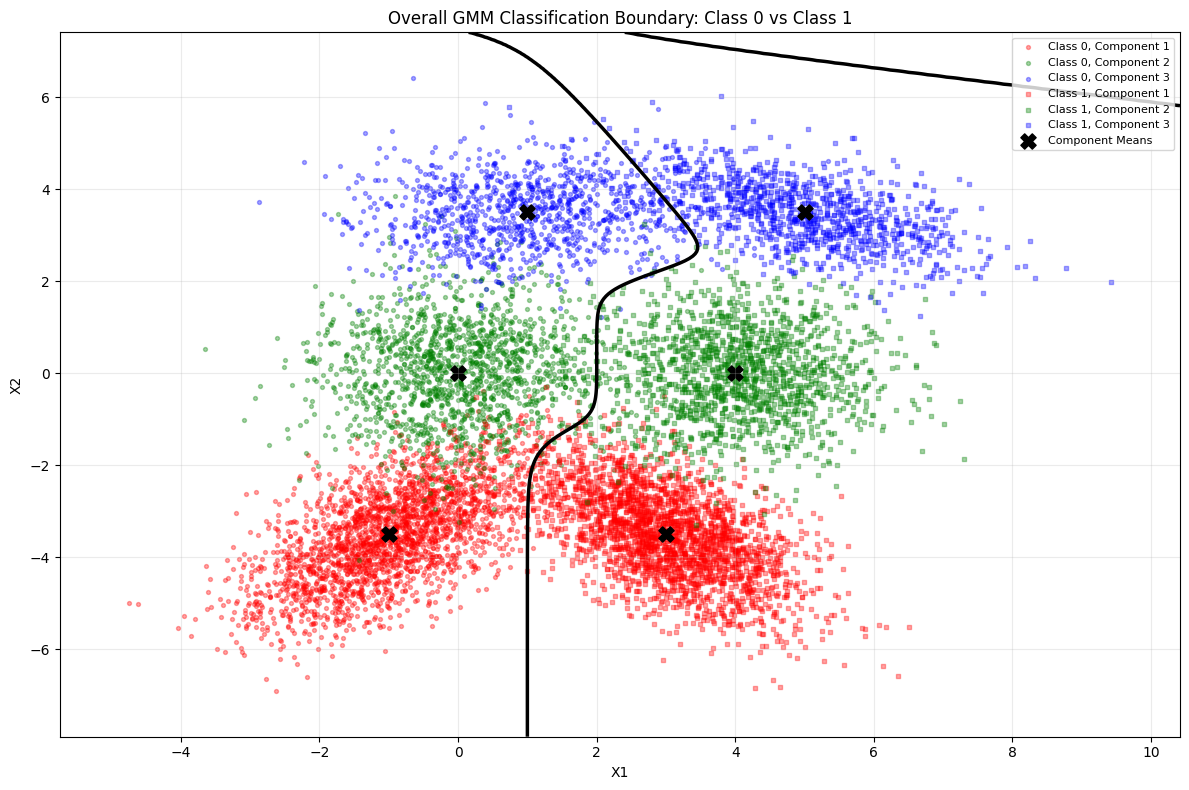

In [12]:
plt.figure(figsize=(12, 8))

colors = ["red", "green", "blue"]

for cls in range(2):
    X = class_data[cls]
    labels = class_component_labels[cls]

    for k in range(K):
        points = X[labels == k]
        plt.scatter(
            points[:, 0], points[:, 1],
            color=colors[k], marker=["o", "s"][cls],
            s=8, alpha=0.35,
            label=f"Class {cls}, Component {k + 1}"
        )

x_min = min(X[:, 0].min() for X in class_data) - 1
x_max = max(X[:, 0].max() for X in class_data) + 1
y_min = min(X[:, 1].min() for X in class_data) - 1
y_max = max(X[:, 1].max() for X in class_data) + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

density0 = np.array([
    gmm_density(point, class_means[0], class_covariances[0], weights)
    for point in grid
]).reshape(xx.shape)

density1 = np.array([
    gmm_density(point, class_means[1], class_covariances[1], weights)
    for point in grid
]).reshape(xx.shape)

plt.contour(
    xx, yy, density0 - density1,
    levels=[0], colors="black", linewidths=2.5
)

plt.scatter(
    np.vstack(class_means)[:, 0],
    np.vstack(class_means)[:, 1],
    color="black", marker="X", s=120,
    label="Component Means"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Overall GMM Classification Boundary: Class 0 vs Class 1")
plt.legend(loc="best", fontsize=8)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()